<a href="https://colab.research.google.com/github/rohillatanisha676-del/CODSOFT_TASKNO/blob/main/SPAM_SMS_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (5169, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

 Naive Bayes
              precision    recall  f1-score   support

  Legitimate       0.96      1.00      0.98       903
        Spam       1.00      0.73      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034


 Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.98      0.99      0.99       903
        Spam       0.94      0.89      0.91       131

    accuracy   

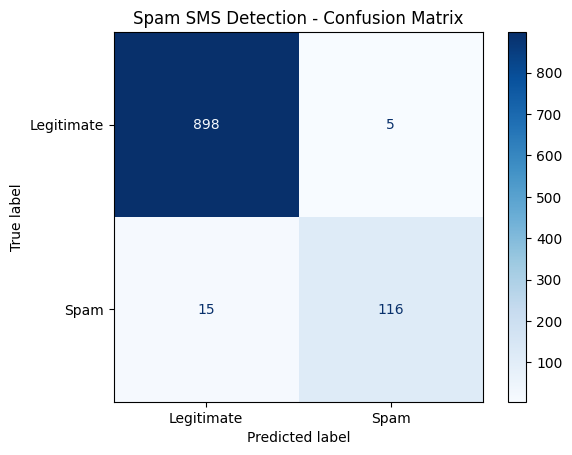


Prediction: SPAM


In [1]:
# ==========================================
# SPAM SMS DETECTION USING MACHINE LEARNING
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    ConfusionMatrixDisplay
)

# 1. Load dataset
df = pd.read_csv("/content/spam.csv", encoding="latin1")

# 2. Select label and message columns
df = df.rename(columns={"v1": "label", "v2": "message"})
df = df[["label", "message"]].dropna()

# Remove duplicate messages
df = df.drop_duplicates()

print("Dataset shape:", df.shape)
print(df.head())
print("\nLabel distribution:")
print(df["label"].value_counts())

# 3. Convert labels into binary values
# ham = legitimate, spam = unwanted message
X = df["message"].astype(str)
y = df["label"].str.lower().map({"ham": 0, "spam": 1})

# Remove rows with unexpected labels, if any
valid = y.notna()
X = X[valid]
y = y[valid].astype(int)

# 4. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Create machine learning models using TF-IDF
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "SVM": LinearSVC(class_weight="balanced", random_state=42)
}

results = []
trained_models = {}

# 6. Train and evaluate each model
for name, classifier in models.items():

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            max_features=10000
        )),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, predictions, zero_division=0) * 100, 2
        )
    })

    print("\n", name)
    print(classification_report(
        y_test, predictions,
        labels=[0, 1],
        target_names=["Legitimate", "Spam"],
        zero_division=0
    ))

# 7. Compare model results
results_df = pd.DataFrame(results)
print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

# 8. Select best model based on F1-score
best_name = results_df.loc[
    results_df["F1 Score (%)"].idxmax(), "Model"
]
best_model = trained_models[best_name]

print("\nBest model based on F1-score:", best_name)

# 9. Plot confusion matrix
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["Legitimate", "Spam"],
    cmap="Blues"
)
plt.title("Spam SMS Detection - Confusion Matrix")
plt.show()

# 10. Test a new SMS message
message = ["Congratulations! You have won a free prize. Call now!"]
prediction = best_model.predict(message)[0]

if prediction == 1:
    print("\nPrediction: SPAM")
else:
    print("\nPrediction: LEGITIMATE")